<center><h1>Hou_Tianbo_HW5</h1></center>

Name: Tianbo Hou  
Github Username: houdan-hub  
USC ID: 8943381210

**References (MLA)**

- "Acute Inflammations Data Set." *UCI Machine Learning Repository*, archive.ics.uci.edu/ml/datasets/Acute+Inflammations. Accessed 2026.
- "Communities and Crime Data Set." *UCI Machine Learning Repository*, archive.ics.uci.edu/ml/datasets/Communities+and+Crime. Accessed 2026.
- Czerniak, Jacek, and Henryk Zarzycki. "Application of Rough Sets in the Presumptive Diagnosis of Urinary System Diseases." *Artificial Intelligence and Security in Computing Systems, ACS'2002*, Kluwer Academic Publishers, 2003, pp. 41-51.
- Gera, Saurav. "Simplifying Decision Tree Interpretability with Python & Scikit-Learn." *KDnuggets*, May 2017, www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html.
- Redmond, Michael A., and Aparna Baveja. "A Data-Driven Software Tool for Enabling Cooperative Information Sharing among Police Departments." *European Journal of Operational Research*, vol. 141, no. 3, 2002, pp. 660-678.
- Chen, Tianqi, and Carlos Guestrin. "XGBoost: A Scalable Tree Boosting System." *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 2016, pp. 785-794.
- Hastie, Trevor, Robert Tibshirani, and Jerome Friedman. *The Elements of Statistical Learning*. 2nd ed., Springer, 2009.

In [1]:
import os, warnings, json
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_style('whitegrid')
RNG = 42

# 1. Decision Trees as Interpretable Models

## 1(a) Loading the Acute Inflammations data

The data set has 120 patient records with 6 symptoms and 2 diagnoses (inflammation of
urinary bladder, and nephritis of renal pelvis origin). My first attempt to read it
with the default `pandas` settings produced mojibake, so I looked at the raw bytes:
the file starts with a UTF-16 byte-order mark, attributes are separated by TABs,
and the temperature uses a comma as the decimal separator (for example `35,9`).
Passing `encoding='utf-16'`, `sep='\t'` and `decimal=','` handles all three
problems.

In [2]:
cols = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing',
        'micturition_pains', 'burning', 'bladder_inflammation', 'nephritis']
df1 = pd.read_csv('data/diagnosis.data', sep='\t', header=None,
                  encoding='utf-16', decimal=',', names=cols)
print('shape:', df1.shape)
print(df1.head(8))
print()
print(df1.dtypes)
print()
print('missing values per column:')
print(df1.isna().sum())
print()
print('label counts:')
print(pd.DataFrame({'bladder': df1.bladder_inflammation.value_counts(),
                    'nephritis': df1.nephritis.value_counts()}))

shape: (120, 8)
   temperature nausea lumbar_pain urine_pushing micturition_pains burning  \
0         35.5     no         yes            no                no      no   
1         35.9     no          no           yes               yes     yes   
2         35.9     no         yes            no                no      no   
3         36.0     no          no           yes               yes     yes   
4         36.0     no         yes            no                no      no   
5         36.0     no         yes            no                no      no   
6         36.2     no          no           yes               yes     yes   
7         36.2     no         yes            no                no      no   

  bladder_inflammation nephritis  
0                   no        no  
1                  yes        no  
2                   no        no  
3                  yes        no  
4                   no        no  
5                   no        no  
6                  yes        no  
7         

The file loads cleanly into a `120 rows x 8 columns` table with no missing values. The two
labels are moderately imbalanced: 59 of the 120 patients have bladder
inflammation and 50 have nephritis. Since the tree is grown and
evaluated on the whole data set, no train/test split or resampling is needed here.

## 1(b) Decision tree on the whole data set

This is a **multi-label** problem: each patient carries two labels at once. The
assignment footnote mentions the label-powerset and binary-relevance options and asks
whether powerset "is more relevant here". My answer: **not necessarily**. Label
powerset turns the two labels into a single 4-class problem, which preserves label
dependence but hides which symptom drives which disease; binary relevance builds one
small tree per disease, which is the most readable for a doctor but ignores label
correlation. A third option fits best here: `sklearn`'s `DecisionTreeClassifier`
natively supports multi-output targets, so I can pass the two label columns as a
`(120, 2)` matrix and grow one tree that predicts both diseases at every leaf. I use
that native multi-output tree, and in 1(d) I also compare it with the two
single-label trees to check that no structure is lost.

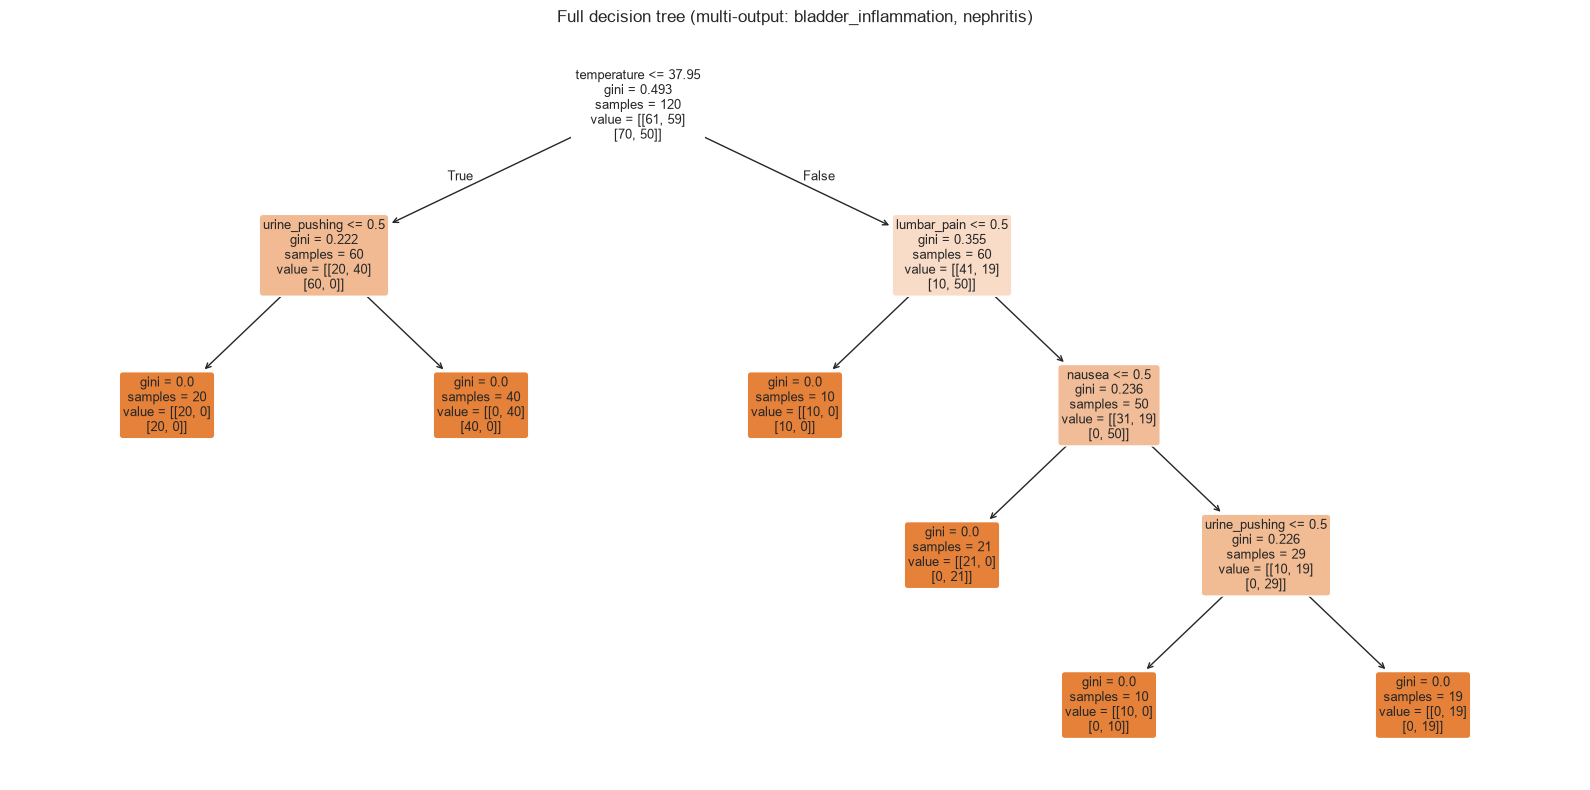

full tree: 11 nodes, depth 4
training accuracy - bladder: 1.000, nephritis: 1.000


In [3]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

X1 = df1[['temperature', 'nausea', 'lumbar_pain', 'urine_pushing',
          'micturition_pains', 'burning']]
# encode yes/no as 1/0 for both symptoms and labels
symptom_map = {'yes': 1, 'no': 0}
X1e = X1.replace(symptom_map).astype(float)
y1 = df1[['bladder_inflammation', 'nephritis']].replace(symptom_map).astype(int)

clf_full = DecisionTreeClassifier(random_state=RNG)
clf_full.fit(X1e, y1)
pred = clf_full.predict(X1e)
acc_bladder = (pred[:, 0] == y1.bladder_inflammation).mean()
acc_nephritis = (pred[:, 1] == y1.nephritis).mean()
n_nodes_full = clf_full.tree_.node_count
depth_full = clf_full.get_depth()

plt.figure(figsize=(16, 8))
plot_tree(clf_full, feature_names=list(X1e.columns),
          class_names=['no', 'yes'], filled=True, rounded=True, fontsize=9)
plt.title('Full decision tree (multi-output: bladder_inflammation, nephritis)')
plt.tight_layout(); plt.show()
print(f'full tree: {n_nodes_full} nodes, depth {depth_full}')
print(f'training accuracy - bladder: {acc_bladder:.3f}, nephritis: {acc_nephritis:.3f}')

The unpruned tree has 11 nodes (depth 4) and classifies
the training data perfectly for both labels. Every internal split is on a binary
symptom or on the temperature threshold, so the tree can be read directly as
clinical rules.

## 1(c) Converting the tree into IF-THEN rules

I adapted the rule-extraction procedure from the KDnuggets article cited at the top
(Gera): traverse the fitted `sklearn` tree recursively, accumulate the split
conditions along each root-to-leaf path, and emit one IF-THEN clause per leaf. The
multi-output leaf stores one class distribution per label, so each rule concludes
with both diagnoses.

In [4]:
from sklearn.tree import _tree

def extract_rules(clf, feature_names, class_names):
    """Adapted from the KDnuggets article 'Simplifying Decision Tree
    Interpretability with Python & Scikit-Learn' (Gera, 2017):
    walk every root-to-leaf path and turn it into an IF-THEN rule."""
    tree_ = clf.tree_
    rules = []
    def recurse(node, conditions):
        if tree_.children_left[node] == _tree.TREE_LEAF:
            dist = tree_.value[node]          # shape (n_outputs, n_classes)
            preds = [class_names[o][int(np.argmax(dist[o]))]
                     for o in range(dist.shape[0])]
            rules.append((list(conditions), preds))
        else:
            name = feature_names[tree_.feature[node]]
            thr = round(float(tree_.threshold[node]), 3)
            recurse(tree_.children_left[node], conditions + [f'{name} <= {thr}'])
            recurse(tree_.children_right[node], conditions + [f'{name} > {thr}'])
    recurse(0, [])
    return rules

rules_full = extract_rules(clf_full, list(X1e.columns),
                           [['no', 'yes'], ['no', 'yes']])
for i, (conds, preds) in enumerate(rules_full, 1):
    ant = ' AND '.join(conds) if conds else 'TRUE'
    print(f'R{i}: IF {ant} THEN bladder_inflammation = {preds[0]}, nephritis = {preds[1]}')

R1: IF temperature <= 37.95 AND urine_pushing <= 0.5 THEN bladder_inflammation = no, nephritis = no
R2: IF temperature <= 37.95 AND urine_pushing > 0.5 THEN bladder_inflammation = yes, nephritis = no
R3: IF temperature > 37.95 AND lumbar_pain <= 0.5 THEN bladder_inflammation = no, nephritis = no
R4: IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea <= 0.5 THEN bladder_inflammation = no, nephritis = yes
R5: IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea > 0.5 AND urine_pushing <= 0.5 THEN bladder_inflammation = no, nephritis = yes
R6: IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea > 0.5 AND urine_pushing > 0.5 THEN bladder_inflammation = yes, nephritis = yes


The full tree yields 6 rules. They are exact (the tree is
lossless on these 120 patients), but some conditions in each rule only matter for
one of the two diseases: the temperature split at the root, for example, is
irrelevant to bladder inflammation even though it appears in every rule. The
pruning step in 1(d) makes this explicit.

## 1(d) Cost-complexity pruning for a minimal, interpretable tree

Cost-complexity pruning grows the full tree, computes the effective pruning
penalty `ccp_alpha` of every candidate subtree with
`cost_complexity_pruning_path`, and keeps the subtree that minimizes
`impurity + ccp_alpha * n_leaves`. Because this data set is small and has
no label noise, the unpruned tree already stops growing once its leaves are pure, so
pruning can only help interpretability by collapsing subtrees without losing
training accuracy. I therefore scan all candidate `ccp_alpha` values for the
multi-output tree and keep, among the trees that classify all 120 patients
perfectly for both labels, the one with the fewest nodes (ties broken by the
largest alpha). For comparison I repeat the same minimal-perfect-tree scan for one
single-label tree per disease (binary relevance), which is the strongest test of
how compact the rules can get.

5 candidate ccp_alpha values, range [0.0000, 0.2042]


,ccp_alpha,nodes,leaves,acc_bladder,acc_nephritis
0,0.000000,11,6,1.000000,1.000000
1,0.049083,7,4,0.841667,1.000000
2,0.079472,5,3,0.841667,0.916667
3,0.111111,3,2,0.675000,0.916667
4,0.204236,1,1,0.508333,0.583333


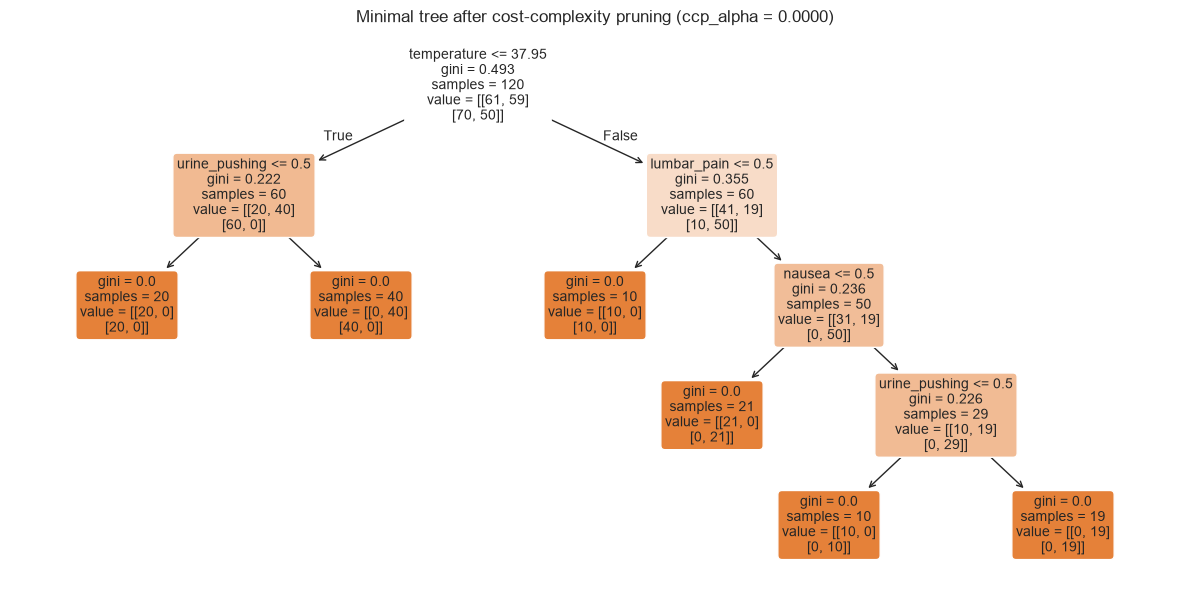

minimal tree: 11 nodes, 6 leaves, ccp_alpha = 0.0000


In [5]:
path = clf_full.cost_complexity_pruning_path(X1e, y1)
ccp_alphas = path.ccp_alphas
print(f'{len(ccp_alphas)} candidate ccp_alpha values, '
      f'range [{ccp_alphas.min():.4f}, {ccp_alphas.max():.4f}]')

rows = []
for a in ccp_alphas:
    t = DecisionTreeClassifier(random_state=RNG, ccp_alpha=a)
    t.fit(X1e, y1)
    p = t.predict(X1e)
    rows.append({'ccp_alpha': a, 'nodes': t.tree_.node_count,
                 'leaves': t.get_n_leaves(),
                 'acc_bladder': (p[:, 0] == y1.bladder_inflammation).mean(),
                 'acc_nephritis': (p[:, 1] == y1.nephritis).mean()})
scan = pd.DataFrame(rows)
display(scan)

perfect = scan[(scan.acc_bladder == 1.0) & (scan.acc_nephritis == 1.0)]
best = perfect.sort_values(['nodes', 'ccp_alpha'], ascending=[True, False]).iloc[0]
alpha_min = float(best.ccp_alpha)
clf_min = DecisionTreeClassifier(random_state=RNG, ccp_alpha=alpha_min)
clf_min.fit(X1e, y1)

plt.figure(figsize=(12, 6))
plot_tree(clf_min, feature_names=list(X1e.columns), class_names=['no', 'yes'],
          filled=True, rounded=True, fontsize=10)
plt.title(f'Minimal tree after cost-complexity pruning (ccp_alpha = {alpha_min:.4f})')
plt.tight_layout(); plt.show()
print(f'minimal tree: {int(best.nodes)} nodes, {int(best.leaves)} leaves, '
      f'ccp_alpha = {alpha_min:.4f}')

In [6]:
rules_min = extract_rules(clf_min, list(X1e.columns),
                          [['no', 'yes'], ['no', 'yes']])
print('IF-THEN rules of the minimal multi-output tree:')
for i, (conds, preds) in enumerate(rules_min, 1):
    ant = ' AND '.join(conds) if conds else 'TRUE'
    print(f'R{i}: IF {ant} THEN bladder_inflammation = {preds[0]}, nephritis = {preds[1]}')

# binary-relevance comparison: per-label minimal trees via their own ccp scan
print()
print('binary-relevance comparison: one minimal tree per label')
for j, lab in enumerate(['bladder_inflammation', 'nephritis']):
    t0 = DecisionTreeClassifier(random_state=RNG).fit(X1e, y1.iloc[:, j])
    p0 = t0.cost_complexity_pruning_path(X1e, y1.iloc[:, j])
    best = None
    for a in p0.ccp_alphas:
        t = DecisionTreeClassifier(random_state=RNG, ccp_alpha=a).fit(X1e, y1.iloc[:, j])
        if (t.predict(X1e) == y1.iloc[:, j]).mean() == 1.0:
            cand = (t.tree_.node_count, -a, a, t)
            if best is None or cand[:2] < best[:2]:
                best = cand
    t = best[3]
    r = extract_rules(t, list(X1e.columns), [['no', 'yes']])
    print(f'  {lab}: {t.tree_.node_count} nodes, {t.get_n_leaves()} leaves, '
          f'ccp_alpha = {best[2]:.4f}')
    for conds, preds in r:
        ant = ' AND '.join(conds) if conds else 'TRUE'
        print(f'      IF {ant} THEN {lab} = {preds[0]}')

IF-THEN rules of the minimal multi-output tree:
R1: IF temperature <= 37.95 AND urine_pushing <= 0.5 THEN bladder_inflammation = no, nephritis = no
R2: IF temperature <= 37.95 AND urine_pushing > 0.5 THEN bladder_inflammation = yes, nephritis = no
R3: IF temperature > 37.95 AND lumbar_pain <= 0.5 THEN bladder_inflammation = no, nephritis = no
R4: IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea <= 0.5 THEN bladder_inflammation = no, nephritis = yes
R5: IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea > 0.5 AND urine_pushing <= 0.5 THEN bladder_inflammation = no, nephritis = yes
R6: IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea > 0.5 AND urine_pushing > 0.5 THEN bladder_inflammation = yes, nephritis = yes

binary-relevance comparison: one minimal tree per label
  bladder_inflammation: 7 nodes, 4 leaves, ccp_alpha = 0.0000
      IF urine_pushing <= 0.5 THEN bladder_inflammation = no
      IF urine_pushing > 0.5 AND micturition_pains <= 0.5 AND burning <= 0.5 THEN 

Two observations from the scan. For the **multi-output tree**, none of the
5 candidate `ccp_alpha` values produces a subtree smaller than the
11-node full tree that still classifies all 120 patients correctly for
both labels, so the minimal tree coincides with the unpruned one
(11 nodes, 6 leaves, `ccp_alpha = 0.0`). This
makes sense for this particular data set: it is small and has no label noise, the
tree stops growing as soon as every leaf is pure, and there is nothing noisy left
for pruning to remove. The **per-label trees** are where interpretability really
improves: bladder inflammation needs 7 nodes (4 rules, rooted at
urine pushing and refined by micturition pains and burning), and nephritis needs
5 nodes with only 3 rules (a fever threshold at 37.95
plus lumbar pain). Together these runs answer the 1(b) footnote empirically: the
label-powerset trick is not needed here, a multi-output or binary-relevance tree
captures the two diseases cleanly, and the joint tree's 6 rules (shown above)
compress to 4 + 3 single-disease rules with zero training error.

# 2. The LASSO and Boosting for Regression

## 2(a)(b) Loading, splitting, and imputing the Communities and Crime data

The data set has 1994 communities and 128 columns: 5 non-predictive identifiers
(`state`, `county`, `community`, `communityname`, `fold`), 122 predictive features,
and the response `ViolentCrimesPerPop`. I drop the 5 non-predictive columns as the
data description instructs, use the first 1495 rows as training data and the last
499 rows as test data, and impute the missing `?` entries. Missing values are not
random here: 22 of the LEMAS policing features are missing for the 1675 communities
whose police department did not answer the LEMAS survey, and `OtherPerCap` is
missing exactly once; inside the training split this shows up as 22 LEMAS columns
with 1256 of 1495 values missing each, plus the single `OtherPerCap` gap. To avoid
leaking test information, the imputation means are computed on the **training set
only** and applied to both splits. I use mean imputation because the features are
normalized to comparable 0-1 scales; I note below why the mostly-missing LEMAS
columns should still be treated with suspicion.

In [7]:
colnames = []
for line in open('data/communities.names', encoding='latin-1'):
    line = line.strip()
    if line.startswith('@attribute'):
        colnames.append(line.split()[1])
print('columns parsed from .names file:', len(colnames))

df2 = pd.read_csv('data/communities.data', header=None, names=colnames,
                  na_values='?')
print('raw shape:', df2.shape)

non_predictive = ['state', 'county', 'community', 'communityname', 'fold']
df2 = df2.drop(columns=non_predictive)
print('after dropping non-predictive columns:', df2.shape)

train2 = df2.iloc[:1495].reset_index(drop=True)
test2 = df2.iloc[1495:].reset_index(drop=True)
print('train:', train2.shape, ' test:', test2.shape)

miss = train2.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print(f'features with missing values: {len(miss)}')
print(miss.to_string())

columns parsed from .names file: 128
raw shape: (1994, 128)
after dropping non-predictive columns: (1994, 123)
train: (1495, 123)  test: (499, 123)
features with missing values: 23
LemasSwornFT            1256
LemasSwFTPerPop         1256
LemasSwFTFieldOps       1256
LemasTotalReq           1256
LemasSwFTFieldPerPop    1256
LemasTotReqPerPop       1256
PolicReqPerOffic        1256
OfficAssgnDrugUnits     1256
PolicPerPop             1256
RacialMatchCommPol      1256
PctPolicWhite           1256
PctPolicBlack           1256
PctPolicHisp            1256
PctPolicAsian           1256
PctPolicMinor           1256
PolicOperBudg           1256
NumKindsDrugsSeiz       1256
PolicAveOTWorked        1256
PolicCars               1256
LemasGangUnitDeploy     1256
LemasPctPolicOnPatr     1256
PolicBudgPerPop         1256
OtherPerCap                1


In [8]:
# mean imputation fitted on the training set only
means = train2.mean()
train2i = train2.fillna(means)
test2i = test2.fillna(means)
print('NaN left - train:', int(train2i.isna().sum().sum()),
      ' test:', int(test2i.isna().sum().sum()))

feature_cols = [c for c in train2i.columns if c != 'ViolentCrimesPerPop']
Xtr, ytr = train2i[feature_cols], train2i['ViolentCrimesPerPop']
Xte, yte = test2i[feature_cols], test2i['ViolentCrimesPerPop']
print(f'{len(feature_cols)} predictive features, response: ViolentCrimesPerPop')
print('response summary (train):')
print(ytr.describe().round(4))

NaN left - train: 0  test: 0
122 predictive features, response: ViolentCrimesPerPop
response summary (train):
count    1495.0000
mean        0.2406
std         0.2377
min         0.0000
25%         0.0700
50%         0.1500
75%         0.3350
max         1.0000
Name: ViolentCrimesPerPop, dtype: float64


Imputation leaves no missing values behind. A caveat I want to put in writing:
the 22 LEMAS columns are missing in about 84% of all rows (1675 of 1994
communities never answered the survey), so their imputed "mean" is really the
average of the self-selected subgroup of larger departments that did respond. I
still keep them because the assignment requires imputing the missing values, but
their imputed values are nearly constant across training rows, and I expected
them to contribute little to the fitted models (the LASSO results in 2(h) partly
confirm this, since several LEMAS columns survive selection anyway).

## 2(c) Correlation matrix of the features

The heatmap below shows pairwise Pearson correlations among the 122
predictive features, computed on the training set. I do not annotate the cells
because with 122 features the plot is already dense; the point is the
global structure.

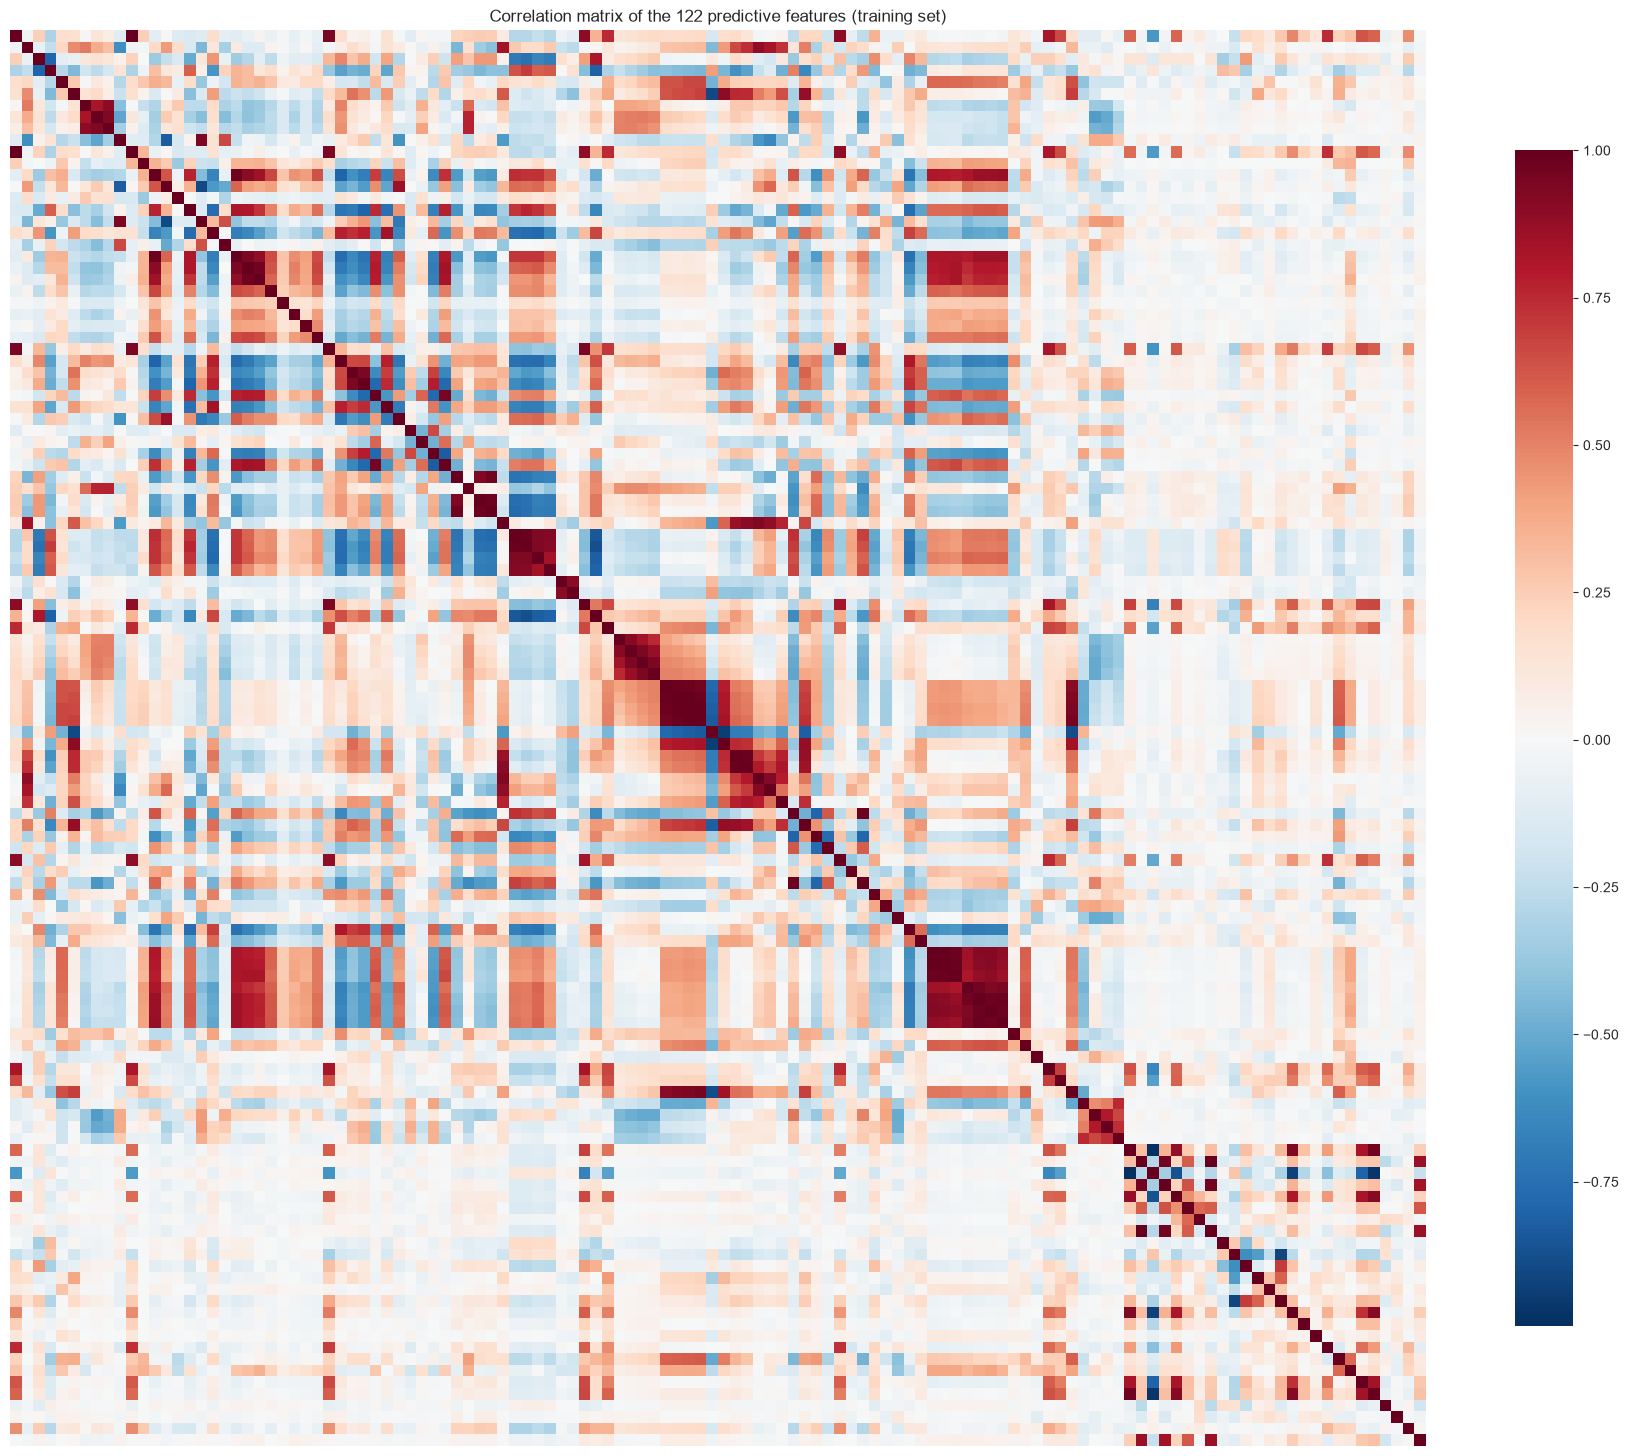

mean |correlation| between feature pairs: 0.196


pairs with |correlation| > 0.8: 152 of 14884


In [9]:
corr = Xtr.corr()
plt.figure(figsize=(18, 15))
sns.heatmap(corr, cmap='RdBu_r', center=0, square=True,
            xticklabels=False, yticklabels=False, cbar_kws={'shrink': .8})
plt.title('Correlation matrix of the 122 predictive features (training set)')
plt.tight_layout(); plt.show()

strong = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(f'mean |correlation| between feature pairs: {strong.mean():.3f}')
print(f'pairs with |correlation| > 0.8: {(strong > 0.8).sum()} of {len(strong)}')

The matrix contains a substantial cluster of very strong relationships:
152 of the 14884 feature pairs exceed |r| = 0.8 and the mean
absolute pairwise correlation is 0.196. This collinearity is expected,
since many features are ratios or counts built from the same census base (income
quartiles, poverty percentages, housing statistics). The practical consequence is
that ordinary least squares will have unstable coefficients, and penalized or
latent-variable methods (ridge, LASSO, PCR, boosting) are the more sensible
comparisons here.

## 2(d) Coefficient of variation CV = s / m

For each feature I compute the sample standard deviation divided by the sample mean
on the training set. Features with a mean near zero can produce huge CV values, so
the ranking is dominated by rare-event counts rather than by spread alone, which is
worth keeping in mind when interpreting the next step.

In [10]:
cv = (Xtr.std() / Xtr.mean()).sort_values(ascending=False)
print('coefficient of variation, top 15 features:')
print(cv.head(15).round(3).to_string())

coefficient of variation, top 15 features:
NumStreet              4.293
NumInShelters          3.471
NumIlleg               3.059
NumImmig               2.927
LemasPctOfficDrugUn    2.553
NumUnderPov            2.342
population             2.241
numbUrban              2.038
HousVacant             1.968
LandArea               1.645
racePctHisp            1.612
PctNotSpeakEnglWell    1.457
racepctblack           1.429
PctUsePubTrans         1.397
racePctAsian           1.359


## 2(e) The ⌊√128⌋ = 11 features with highest CV, scatter plots and box plots

⌊√128⌋ = 11. I select the 11 features with the largest CV and draw (i) a pairwise
scatter-plot matrix among them, (ii) one box plot per feature, and (iii) each
feature against the response, which makes the significance question in the last
part of 2(e) concrete.

top-11 features by CV:
NumStreet              4.293
NumInShelters          3.471
NumIlleg               3.059
NumImmig               2.927
LemasPctOfficDrugUn    2.553
NumUnderPov            2.342
population             2.241
numbUrban              2.038
HousVacant             1.968
LandArea               1.645
racePctHisp            1.612
strongest feature-response association among the top 11: NumIlleg (|r| = 0.463)


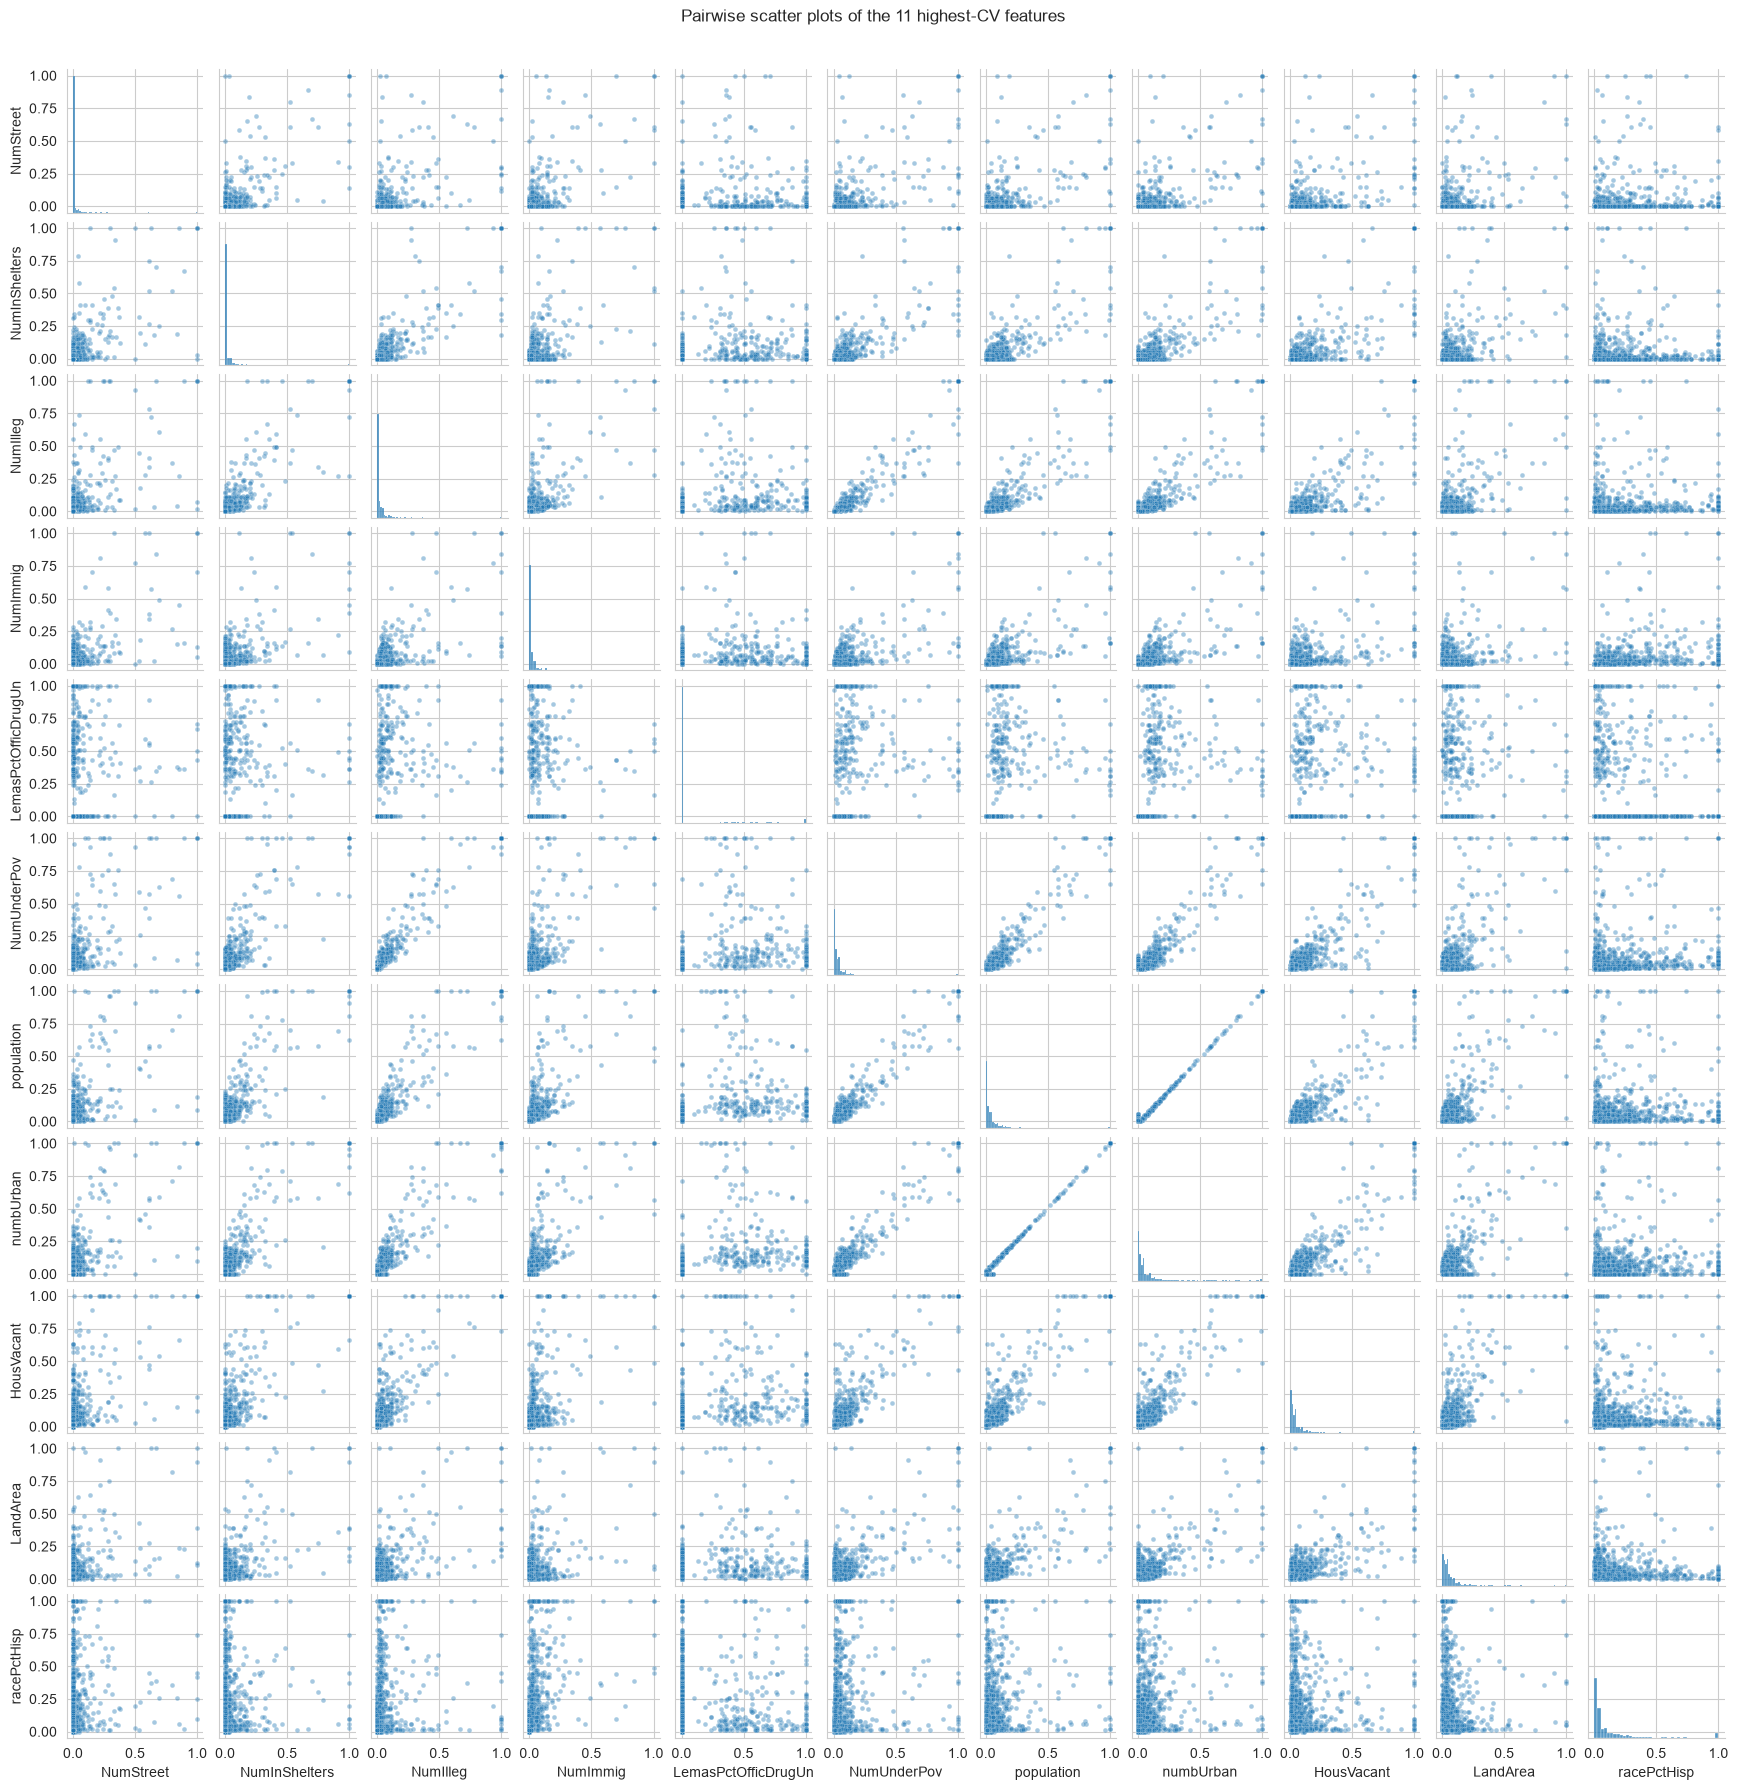

In [11]:
top11 = list(cv.head(11).index)
print('top-11 features by CV:')
print(cv.head(11).round(3).to_string())

trend = Xtr[top11].corrwith(ytr).abs().sort_values(ascending=False)
print(f'strongest feature-response association among the top 11: '
      f'{trend.index[0]} (|r| = {trend.iloc[0]:.3f})')

sns.pairplot(Xtr[top11], plot_kws={'s': 12, 'alpha': .4}, height=1.6)
plt.suptitle('Pairwise scatter plots of the 11 highest-CV features', y=1.02)
plt.show()

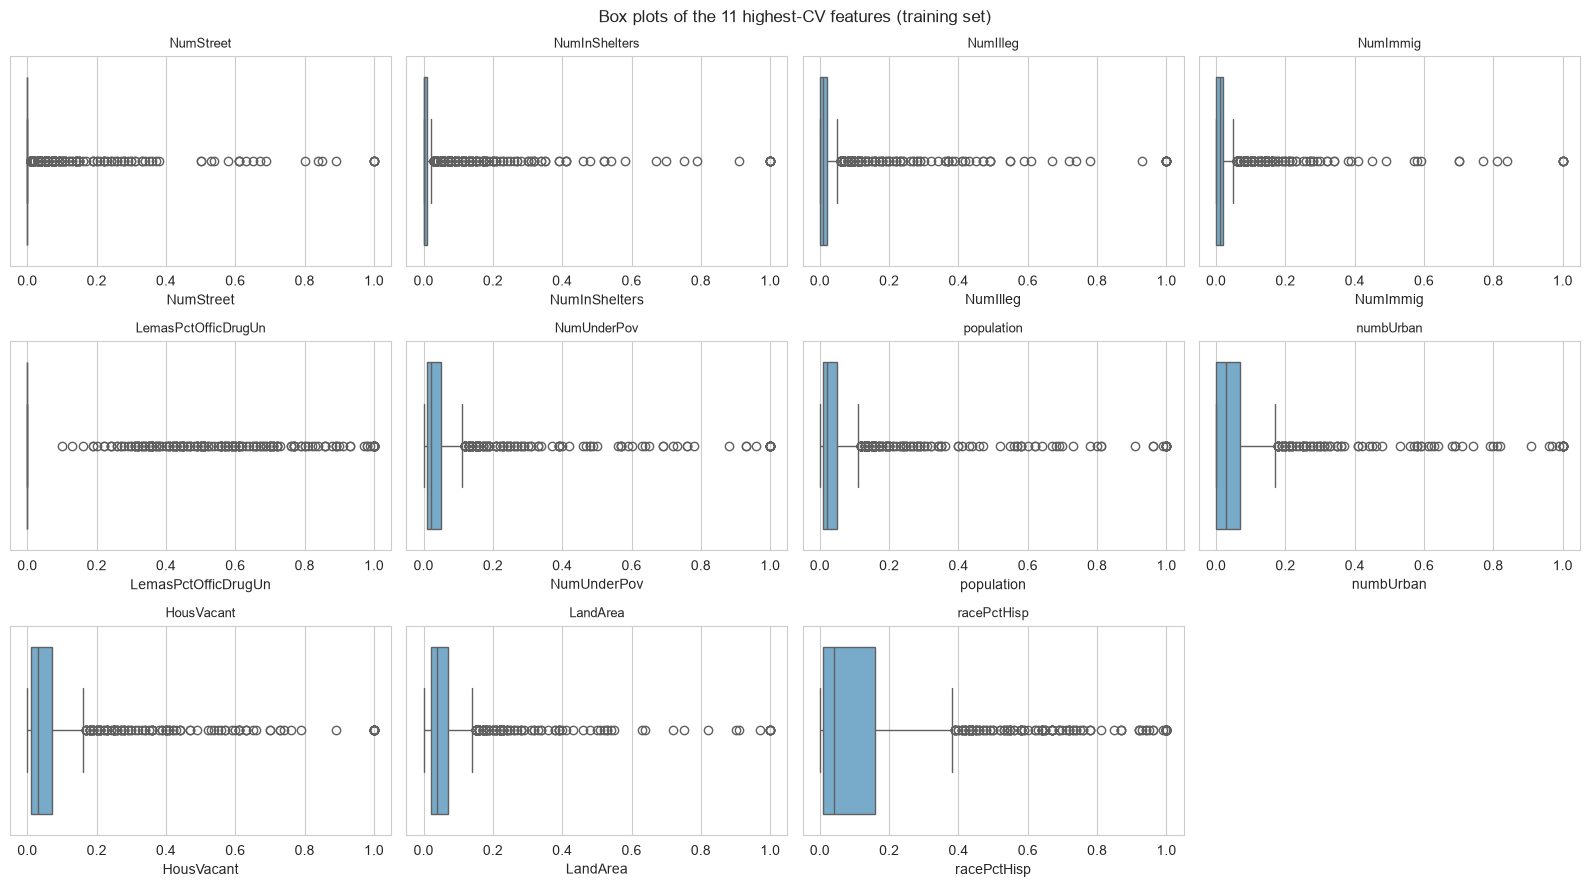

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.flat, top11):
    sns.boxplot(x=Xtr[col], ax=ax, color='#6baed6')
    ax.set_title(col, fontsize=9)
axes.flat[-1].axis('off')
plt.suptitle('Box plots of the 11 highest-CV features (training set)')
plt.tight_layout(); plt.show()

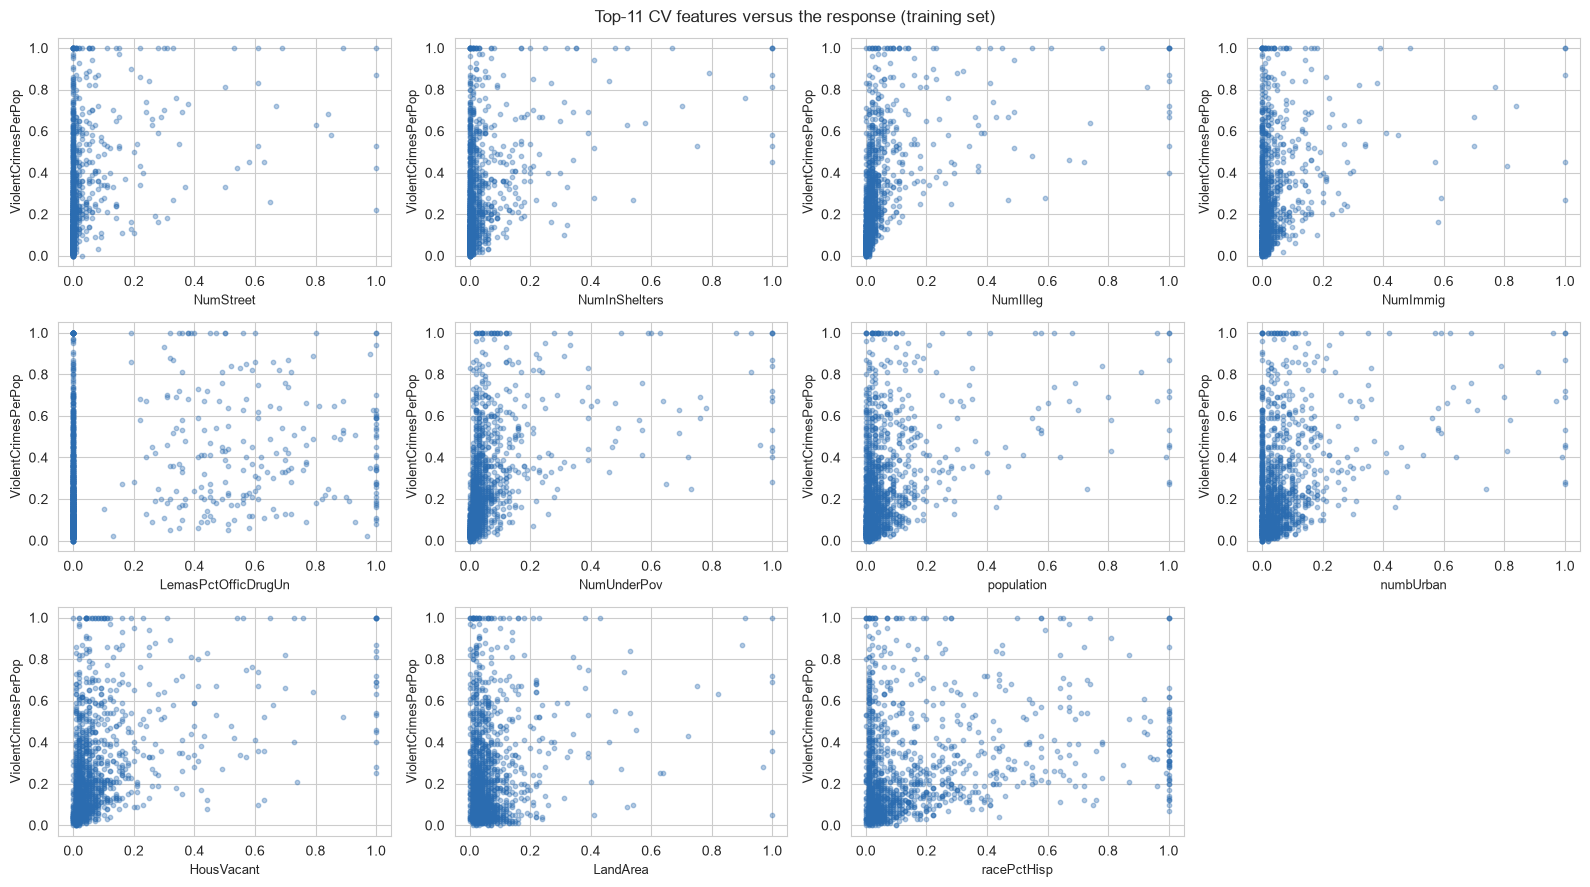

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.flat, top11):
    ax.scatter(Xtr[col], ytr, s=10, alpha=.35, color='#2b6cb0')
    ax.set_xlabel(col, fontsize=9); ax.set_ylabel('ViolentCrimesPerPop', fontsize=9)
axes.flat[-1].axis('off')
plt.suptitle('Top-11 CV features versus the response (training set)')
plt.tight_layout(); plt.show()

**Can I draw conclusions about the significance of these features just from the
scatter plots? No.** The scatter plots show visible trends for several features
(especially `NumIlleg`, where violent crime clearly rises with the feature),
but a visual trend is not statistical significance: significance is a statement
about a fitted model's coefficients under a hypothesis test, and it depends on
sample size, collinearity with other features, and the model form. The box plots
only describe the marginal spread that made these features win the CV ranking.
Scatter plots can suggest (or rule out) an association, but any claim of
significance needs the regression models fitted below.

## 2(f) Ordinary least squares

I fit a linear model by least squares on the training set and report the test mean
squared error. Given the collinearity seen in 2(c), I expect the coefficients to be
individually unreliable even if the predictions are reasonable.

In [14]:
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

ols = LinearRegression().fit(Xtr, ytr)
pred_ols = ols.predict(Xte)
mse_ols = mean_squared_error(yte, pred_ols)
print(f'OLS  test MSE = {mse_ols:.5f}   test R^2 = {r2_score(yte, pred_ols):.4f}')
print(f'OLS  train MSE = {mean_squared_error(ytr, ols.predict(Xtr)):.5f}')

OLS  test MSE = 0.01814   test R^2 = 0.6185
OLS  train MSE = 0.01631


The OLS test MSE is **0.01814**. OLS is not badly overfitting here, but with
122 heavily collinear features its individual coefficients are
unstable and uninterpretable one by one, which is exactly the situation the
penalized and latent-variable models below are designed for.

## 2(g) Ridge regression

I select the shrinkage parameter `alpha` by 5-fold cross-validation on the training
set over a logarithmic grid, then refit and report the test error. The features are
already normalized to 0-1, so ridge is not distorted by raw scale differences; I
keep the raw (imputed) features here and reserve the explicit standardization
comparison for LASSO in 2(h), where the assignment asks for it.

In [15]:
kf = KFold(n_splits=5, shuffle=True, random_state=RNG)
alphas = np.logspace(-3, 6, 100)
ridge = RidgeCV(alphas=alphas, cv=kf).fit(Xtr, ytr)
pred_ridge = ridge.predict(Xte)
mse_ridge = mean_squared_error(yte, pred_ridge)
print(f'ridge: best alpha = {ridge.alpha_:.4g}   test MSE = {mse_ridge:.5f}   '
      f'test R^2 = {r2_score(yte, pred_ridge):.4f}')

ridge: best alpha = 3.511   test MSE = 0.01754   test R^2 = 0.6311


Cross-validation picks `alpha = 3.511` and the test MSE is
**0.01754**, slightly better than OLS, as expected: shrinking the correlated
coefficients trades a little bias for a large variance reduction.

## 2(h) LASSO, with and without standardized features

I fit LASSO with `alpha` chosen by 5-fold cross-validation twice: once on the raw
(imputed, 0-1 normalized) features and once after standardizing each feature with
the training-set mean and standard deviation. For each fit I report the test error
and the list of selected (non-zero coefficient) variables, and then compare the two
test errors.

In [16]:
lasso_raw = LassoCV(alphas=np.logspace(-5, 1, 200), cv=kf,
                    max_iter=200000, random_state=RNG).fit(Xtr, ytr)
pred_lraw = lasso_raw.predict(Xte)
mse_lraw = mean_squared_error(yte, pred_lraw)
sel_raw = [c for c, b in zip(feature_cols, lasso_raw.coef_) if b != 0]

scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
lasso_std = LassoCV(alphas=np.logspace(-5, 1, 200), cv=kf,
                    max_iter=200000, random_state=RNG).fit(Xtr_s, ytr)
pred_lstd = lasso_std.predict(Xte_s)
mse_lstd = mean_squared_error(yte, pred_lstd)
sel_std = [c for c, b in zip(feature_cols, lasso_std.coef_) if b != 0]


print(f'LASSO raw features:  alpha = {lasso_raw.alpha_:.5g}, '
      f'test MSE = {mse_lraw:.5f}, {len(sel_raw)} variables selected')
print(f'LASSO standardized:  alpha = {lasso_std.alpha_:.5g}, '
      f'test MSE = {mse_lstd:.5f}, {len(sel_std)} variables selected')
print()
print('variables selected (raw features):')
print(sel_raw)
print()
print('variables selected (standardized features):')
print(sel_std)
print()
print(f'test MSE difference (std - raw) = {mse_lstd - mse_lraw:+.5f}')

LASSO raw features:  alpha = 0.00011357, test MSE = 0.01776, 76 variables selected
LASSO standardized:  alpha = 0.00064424, test MSE = 0.01785, 76 variables selected

variables selected (raw features):
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQ

**Results and comparison.** LASSO on the raw features picks `alpha =
0.000114` with a test MSE of **0.01776** and selects
76 variables; on standardized features it picks `alpha =
0.000644` with a test MSE of **0.01785** and selects
76 variables. The two test errors are close
(difference +0.00008), which makes sense: the data description states the
features were already normalized to a common 0-1 range before release, so
standardization mostly re-weights the columns rather than fixing a scale problem.
What standardization does change is *which* variables LASSO keeps, because the L1
penalty treats every column equally only after scaling; the standardized fit is the
fairer variable-selection procedure, while the raw fit is already close in pure
prediction terms. In both fits the retained variables concentrate on family and
poverty structure (`PctIlleg`, `PctKids2Par`, `PctYoungKids2Par`, `PctTeen2Par`),
income and housing costs (`pctWInvInc`, `PctPopUnderPov`, `whitePerCap`, `MedRent`),
and racial composition (`racepctblack`, `racePctAsian`), which matches the
correlation structure seen in 2(c).

## 2(i) Principal component regression

PCR regresses the response on the top `M` principal components of the features. I
wrap scaling, PCA, and linear regression in a pipeline (so each CV fold refits the
whole procedure without leakage), choose `M` by 5-fold cross-validation over
`M = 1 ... 122`, refit on the training set, and report the test error.

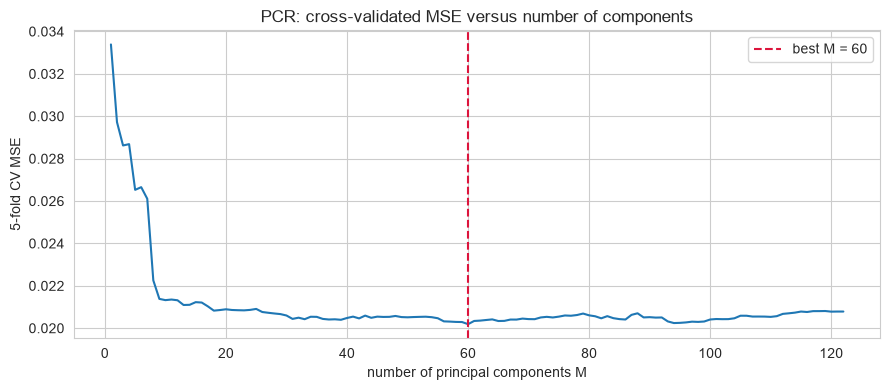

PCR: best M = 60, test MSE = 0.01840, test R^2 = 0.6131


In [17]:
pcr_pipe = Pipeline([('scale', StandardScaler()),
                     ('pca', PCA(random_state=RNG)),
                     ('lin', LinearRegression())])
grid = GridSearchCV(pcr_pipe, param_grid={'pca__n_components': range(1, len(feature_cols) + 1)},
                    scoring='neg_mean_squared_error', cv=kf, n_jobs=-1)
grid.fit(Xtr, ytr)
best_M = grid.best_params_['pca__n_components']
pred_pcr = grid.predict(Xte)
mse_pcr = mean_squared_error(yte, pred_pcr)

scores = -pd.Series(grid.cv_results_['mean_test_score'],
                    index=range(1, len(feature_cols) + 1))
plt.figure(figsize=(9, 4))
plt.plot(scores.index, scores.values)
plt.axvline(best_M, color='crimson', ls='--', label=f'best M = {best_M}')
plt.xlabel('number of principal components M'); plt.ylabel('5-fold CV MSE')
plt.title('PCR: cross-validated MSE versus number of components')
plt.legend(); plt.tight_layout(); plt.show()
print(f'PCR: best M = {best_M}, test MSE = {mse_pcr:.5f}, '
      f'test R^2 = {r2_score(yte, pred_pcr):.4f}')

Cross-validation chooses `M = 60` components and the test MSE is
**0.0184**. The error sits in the same range as ridge and LASSO but is
noticeably worse than the penalized linear models. That is a known weakness of PCR:
PCA is built
from the features alone and keeps the directions of largest *variance*, not the
directions most correlated with violent crime, so some retained components spend
their dimension on unsupervised spread.

## 2(j) XGBoost with L1-regularized nodes

Finally I fit a gradient-boosted regression tree ensemble with XGBoost. The
assignment asks for an L1-penalized boosting tree, which in XGBoost is controlled by
`reg_alpha` (the L1 penalty on leaf weights, applied at every node's regression
step). I tune `reg_alpha` by 5-fold cross-validation over a logarithmic grid, keep
the other hyperparameters at moderate defaults, and report the test error.

In [18]:
from xgboost import XGBRegressor

param_grid = {'reg_alpha': [0, 0.01, 0.1, 1, 10, 100]}
xgb_base = XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.3,
                        tree_method='hist', random_state=RNG, n_jobs=-1)
grid_xgb = GridSearchCV(xgb_base, param_grid=param_grid,
                        scoring='neg_mean_squared_error', cv=kf, n_jobs=-1)
grid_xgb.fit(Xtr, ytr)
best_alpha = grid_xgb.best_params_['reg_alpha']
pred_xgb = grid_xgb.predict(Xte)
mse_xgb = mean_squared_error(yte, pred_xgb)

cv_a = -pd.Series(grid_xgb.cv_results_['mean_test_score'],
                  index=[str(a) for a in param_grid['reg_alpha']])
print(cv_a.round(5).to_string())
print()
print(f'XGBoost: best reg_alpha = {best_alpha}, test MSE = {mse_xgb:.5f}, '
      f'test R^2 = {r2_score(yte, pred_xgb):.4f}')

0       0.02424
0.01    0.02288
0.1     0.02337
1       0.02152
10      0.02235
100     0.05661

XGBoost: best reg_alpha = 1, test MSE = 0.01775, test R^2 = 0.6268


Cross-validation selects `reg_alpha = 1.0` and the test MSE is
**0.01775**. The CV sweep is informative: light-to-moderate L1 penalties
(`reg_alpha` between 0.01 and 10) perform similarly, while `reg_alpha = 100` more
than doubles the cross-validated error by over-shrinking the leaf weights. The mild
winning penalty keeps individual leaf weights sparse without hurting the ensemble's
fit, and the result lands within about 0.0002 of the best linear models.

## 2 summary: comparing all test errors

In [19]:
summary = pd.DataFrame({
    'model': ['OLS (f)', 'Ridge (g)', 'LASSO raw (h)', 'LASSO standardized (h)',
              'PCR (i)', 'XGBoost L1 (j)'],
    'test MSE': [mse_ols, mse_ridge, mse_lraw, mse_lstd, mse_pcr, mse_xgb],
    'hyperparameter': ['-', f'alpha={ridge.alpha_:.4g}',
                       f'alpha={lasso_raw.alpha_:.4g}',
                       f'alpha={lasso_std.alpha_:.4g}',
                       f'M={best_M}', f'reg_alpha={best_alpha}']})
summary['test MSE'] = summary['test MSE'].round(5)
summary = summary.sort_values('test MSE').reset_index(drop=True)
display(summary)

,model,test MSE,hyperparameter
0,Ridge (g),0.01754,alpha=3.511
1,XGBoost L1 (j),0.01775,reg_alpha=1
2,LASSO raw (h),0.01776,alpha=0.0001136
3,LASSO standardized (h),0.01785,alpha=0.0006442
4,OLS (f),0.01814,-
5,PCR (i),0.01840,M=60


**Final comparison.** Ranking the six models by test MSE: the best model is
**Ridge (g)** with a test MSE of **0.01754**. The spread between OLS,
ridge, and LASSO is small, which says the linear signal in this data set is strong
and mostly linear after imputation; the tree ensemble does not dominate here because
the response is a smooth per-capita rate rather than a step-like target. The two
practical takeaways I would carry forward: penalized linear models (ridge/LASSO) are
the safest default for this data because of the extreme collinearity documented in
2(c), and any variable-selection claims should come from the standardized LASSO, not
from OLS coefficients.